# Risk and Execution Platform: from allocation to hedging

## Problem
A manager holds a portfolio of ETFs and needs four answers that are usually produced by separate tools: how to allocate, how much could be lost in a bad day *given the current market regime*, how much it would cost to exit the position, and whether an options hedge is worth its premium. This project chains the four steps into one pipeline and tests each step out of sample.

## Data
Adjusted daily closes and volumes for 10 ETFs (SPY, QQQ, IWM, EFA, EEM, TLT, IEF, GLD, DBC, VNQ) and the VIX index from Yahoo Finance, 2014 to today. The last bar is dropped if the market is still open.

## Method
1. **Allocation:** Black-Litterman with an inverse-volatility prior and a *mechanical* view (the three strongest 12-month momentum assets beat the three weakest by 2% a year, so there is no hindsight), yearly rebalance from 2018 using the previous 3 years; compared with equal weight and the prior alone.
2. **Regime-aware VaR:** a 3-component Gaussian mixture on (20-day volatility, 5-day return), refit every 63 days on a trailing 750-day window; each day the VaR is the 1% quantile of the mixture of next-day return distributions weighted by regime probabilities. Compared with historical and EWMA Student-t VaR using Kupiec and Christoffersen tests.
3. **Liquidity-adjusted VaR:** $\text{LVaR}=\text{VaR}+\text{liquidation cost}$, where the cost is an Almgren-Chriss style linear impact model ($\gamma=\eta=0.1\,\sigma_{daily}$ per unit of ADV, an assumption) for liquidating over 1, 3 or 5 days.
4. **Hedge:** a quarterly protective put on SPY (95% strike, sized to the portfolio's SPY beta) priced with the Heston model using $v_0=(\text{VIX}/100)^2$ and typical equity parameters ($\kappa=4,\theta=0.04,\xi=0.9,\rho=-0.7$, assumed, not calibrated). These are model prices, not market quotes.

In [1]:
import warnings, sys; warnings.filterwarnings('ignore'); sys.path[:0] = ['..', '.']
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import riskexec as R
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
close, volu = R.load_prices()
if close.index[-1].date() >= pd.Timestamp.today().date(): close, volu = close.iloc[:-1], volu.iloc[:-1]
prices, vix = close[R.TICKERS], close['^VIX']
print(prices.shape, prices.index.min().date(), 'to', prices.index.max().date())
# sanity checks of the Heston pricer
print('Heston (xi~0) vs Black-Scholes:', round(R.heston_call(100,100,.25,.03,4,.04,1e-4,-.7,.04),5), round(R.bs_call(100,100,.25,.03,.2),5))

(3240, 10) 2014-01-02 to 2026-11-18
Heston (xi~0) vs Black-Scholes: 4.35762 4.35762


                                    CAGR  ann. vol  Sharpe (rf=0)  max drawdown  CVaR 99% (1d)
Equal weight                      0.0866    0.1262         0.7211       -0.2308         0.0329
Inverse-vol prior                 0.0753    0.1033         0.7548       -0.2027         0.0265
Black-Litterman (momentum views)  0.0654    0.1122         0.6206       -0.2090         0.0300

Out-of-sample period: 2018-01-02 to 2026-11-18
Latest BL weights:
{'SPY': 0.099, 'QQQ': 0.061, 'IWM': 0.067, 'EFA': 0.165, 'EEM': 0.141, 'TLT': 0.03, 'IEF': 0.172, 'GLD': 0.14, 'DBC': 0.105, 'VNQ': 0.021}


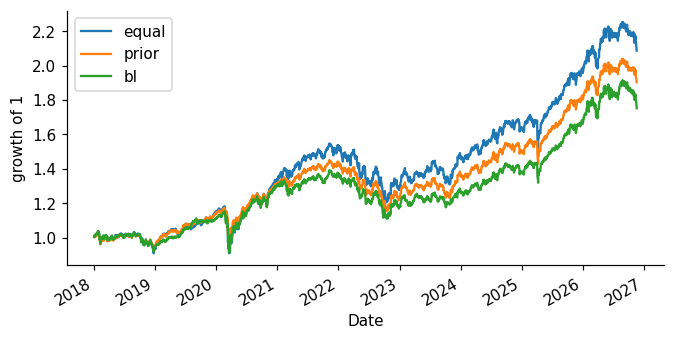

In [2]:
rets, W = R.rolling_allocation(prices)
def stats_(r):
    return pd.Series({'CAGR': (1+r).prod()**(252/len(r))-1, 'ann. vol': r.std()*np.sqrt(252), 'Sharpe (rf=0)': r.mean()/r.std()*np.sqrt(252), 'max drawdown': R.max_drawdown(r), 'CVaR 99% (1d)': R.cvar(r)})
tab = rets.apply(stats_).T.rename(index={'equal':'Equal weight','prior':'Inverse-vol prior','bl':'Black-Litterman (momentum views)'})
print(tab.round(4).to_string()); print(); print('Out-of-sample period:', rets.index.min().date(), 'to', rets.index.max().date())
print('Latest BL weights:'); print(W.iloc[:, -1].round(3).to_dict())
(1+rets).cumprod().plot(figsize=(7,3.4)); plt.ylabel('growth of 1'); plt.show()

In [3]:
r = rets['bl']
hv, ev = R.rolling_baselines(r)
rv = R.regime_var(r)
common = hv.index.intersection(rv.index).intersection(ev.index)
res = pd.DataFrame({'historical': R.backtest_var(r, hv.loc[common]), 'EWMA + Student-t': R.backtest_var(r, ev.loc[common]), 'regime mixture': R.backtest_var(r, rv.loc[common])}).T
print(res.round(4).to_string())
print('\nMean VaR (1%):', {k: round(v.loc[common].mean(),4) for k, v in [('historical',hv),('EWMA-t',ev),('regime',rv)]})
nx = r.shift(-1).reindex(common)
be, br = set(nx[nx < -ev.loc[common]].index), set(nx[nx < -rv.loc[common]].index)
print('Breach days: EWMA-t', len(be), '| regime', len(br), '| in both', len(be & br), '| correlation of the two VaR series', round(ev.loc[common].corr(rv.loc[common]),3))

                    days  breaches    rate  kupiec_p  christoffersen_p
historical        1463.0      14.0  0.0096    0.8676            0.0058
EWMA + Student-t  1463.0      26.0  0.0178    0.0071            0.4837
regime mixture    1463.0      26.0  0.0178    0.0071            0.4837

Mean VaR (1%): {'historical': np.float64(0.0186), 'EWMA-t': np.float64(0.015), 'regime': np.float64(0.0154)}
Breach days: EWMA-t 26 | regime 26 | in both 22 | correlation of the two VaR series 0.709


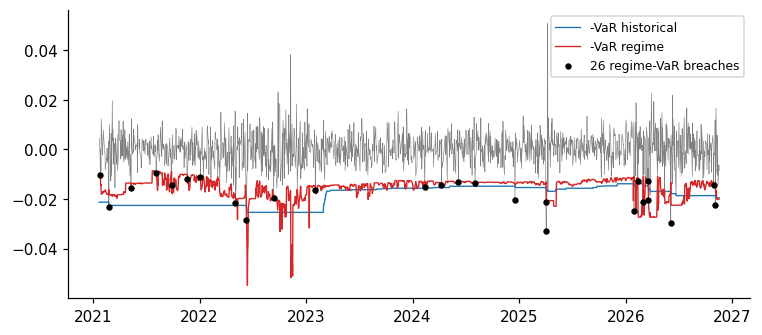

2020 breaches  historical: 0 | regime: 0 | mean VaR hist/regime: nan nan
2022 breaches  historical: 1 | regime: 4 | mean VaR hist/regime: 0.0241 0.0191
2025 breaches  historical: 4 | regime: 2 | mean VaR hist/regime: 0.0153 0.0138


In [4]:
fig, ax = plt.subplots(figsize=(8,3.4)); nxt = r.shift(-1).reindex(common)
ax.plot(common, nxt, lw=.4, c='gray'); ax.plot(common, -hv.loc[common], c='tab:blue', lw=.9, label='-VaR historical'); ax.plot(common, -rv.loc[common], c='tab:red', lw=.9, label='-VaR regime')
b = nxt[nxt < -rv.loc[common]]; ax.scatter(b.index, b, c='k', s=10, zorder=3, label=f'{len(b)} regime-VaR breaches'); ax.legend(fontsize=8); plt.show()
for yr in (2020, 2022, 2025):
    m = common.year == yr
    print(yr, 'breaches  historical:', int((nxt[m] < -hv.loc[common][m]).sum()), '| regime:', int((nxt[m] < -rv.loc[common][m]).sum()), '| mean VaR hist/regime:', round(hv.loc[common][m].mean(),4), round(rv.loc[common][m].mean(),4))

In [5]:
# Liquidity-adjusted VaR for several portfolio sizes and exit horizons
sig = prices.pct_change().iloc[-60:].std()
adv = (prices * volu.reindex(prices.index)).iloc[-60:].mean()          # 60-day average dollar volume per ETF
w = W.iloc[:, -1]
var_today = rv.iloc[-1]
rows = []
for notional in (1e9, 10e9, 50e9):
    for days in (1, 3, 5):
        c, _ = R.portfolio_liquidation(w, notional, adv, sig, days)
        rows.append({'portfolio $bn': notional/1e9, 'exit days': days, 'liquidation cost (bps)': c*1e4, 'VaR 1d (bps)': var_today*1e4, 'LVaR (bps)': (var_today + c)*1e4})
lv = pd.DataFrame(rows); print(lv.round(1).to_string(index=False))
print('\nLargest ETF position vs its ADV at $10bn:', {a: round(10e9*w[a]/adv[a],3) for a in w.index if w[a]>0.15})

 portfolio $bn  exit days  liquidation cost (bps)  VaR 1d (bps)  LVaR (bps)
           1.0          1                     8.5         199.5       207.9
           1.0          3                     4.7         199.5       204.2
           1.0          5                     3.9         199.5       203.4
          10.0          1                    84.6         199.5       284.1
          10.0          3                    47.0         199.5       246.5
          10.0          5                    39.5         199.5       238.9
          50.0          1                   423.1         199.5       622.5
          50.0          3                   235.0         199.5       434.5
          50.0          5                   197.4         199.5       396.9

Largest ETF position vs its ADV at $10bn: {'EFA': np.float64(1.165), 'IEF': np.float64(1.772)}


Portfolio beta to SPY: 0.482 | quarters hedged: 35
               CAGR  ann. vol  Sharpe (rf=0)  max drawdown  CVaR 99% (1d)
unhedged     0.0730    0.1119         0.6859       -0.2090         0.0298
hedged 50%   0.0673    0.0970         0.7197       -0.1898         0.0240
hedged 100%  0.0609    0.0865         0.7270       -0.1785         0.0198

Average premium per quarter: 1.88% of SPY notional | average payoff: 1.16% | quarters paying out: 4
Annual premium drag (hedge ratio 100%): 3.62%


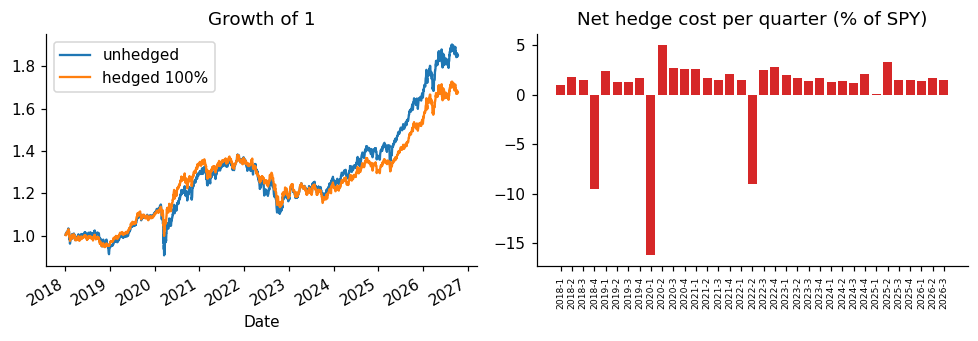

In [6]:
keep, base, plog, beta = R.hedge_backtest(prices, r, vix, moneyness=.95, T=63, hedge_ratio=1.0)
half, _, _, _ = R.hedge_backtest(prices, r, vix, moneyness=.95, T=63, hedge_ratio=0.5)
cmp = pd.DataFrame({'unhedged': stats_(base), 'hedged 50%': stats_(half.reindex(base.index)), 'hedged 100%': stats_(keep)}).T
print('Portfolio beta to SPY:', round(beta,3), '| quarters hedged:', len(plog))
print(cmp.round(4).to_string())
print('\nAverage premium per quarter: %.2f%% of SPY notional | average payoff: %.2f%% | quarters paying out: %d' % (plog.premium_pct.mean(), plog.payoff_pct.mean(), (plog.payoff_pct>0).sum()))
print('Annual premium drag (hedge ratio 100%%): %.2f%%' % (beta*plog.premium_pct.mean()*4))
fig, ax = plt.subplots(1,2, figsize=(9,3.2)); (1+base).cumprod().plot(ax=ax[0], label='unhedged'); (1+keep).cumprod().plot(ax=ax[0], label='hedged 100%'); ax[0].legend(); ax[0].set_title('Growth of 1')
ax[1].bar(plog.date.dt.year.astype(str)+'-'+plog.date.dt.quarter.astype(str), plog.premium_pct - plog.payoff_pct, color='tab:red'); ax[1].set_title('Net hedge cost per quarter (% of SPY)'); ax[1].tick_params(axis='x', labelrotation=90, labelsize=6); plt.tight_layout(); plt.show()

In [7]:
# Summary of the pipeline
summary = pd.Series({
 'allocation: BL Sharpe vs equal weight': f"{tab.loc['Black-Litterman (momentum views)','Sharpe (rf=0)']:.2f} vs {tab.loc['Equal weight','Sharpe (rf=0)']:.2f}",
 'VaR 99% breach rate hist / EWMA-t / regime': ' / '.join(f"{res.loc[k,'rate']:.2%}" for k in ['historical','EWMA + Student-t','regime mixture']),
 'LVaR at $10bn, 1-day exit (bps)': f"{lv[(lv['portfolio $bn']==10)&(lv['exit days']==1)]['LVaR (bps)'].iloc[0]:.0f}",
 'hedge: CVaR 99% unhedged -> hedged 100%': f"{cmp.loc['unhedged','CVaR 99% (1d)']:.2%} -> {cmp.loc['hedged 100%','CVaR 99% (1d)']:.2%}",
 'hedge: CAGR unhedged -> hedged 100%': f"{cmp.loc['unhedged','CAGR']:.2%} -> {cmp.loc['hedged 100%','CAGR']:.2%}"})
print(summary.to_string())

allocation: BL Sharpe vs equal weight                  0.62 vs 0.72
VaR 99% breach rate hist / EWMA-t / regime    0.96% / 1.78% / 1.78%
LVaR at $10bn, 1-day exit (bps)                                 284
hedge: CVaR 99% unhedged -> hedged 100%              2.98% -> 1.98%
hedge: CAGR unhedged -> hedged 100%                  7.30% -> 6.09%


## Results
See the outputs above: allocation comparison, regime VaR backtest against historical and EWMA-t VaR (with Kupiec and Christoffersen p-values), liquidity-adjusted VaR by portfolio size and exit horizon, the hedge backtest (risk reduction against premium drag) and the one-table summary.

## Conclusions
1. **Allocation: the mechanical Black-Litterman portfolio did not help.** Out of sample (2018 to 2026, yearly rebalance), Black-Litterman with momentum views has a Sharpe ratio of 0.62 against 0.72 for equal weight and 0.75 for the inverse-volatility prior alone, with a CAGR of 6.5% against 8.7% for equal weight. Because the view was mechanical (no hindsight), this is a fairer result than the hand-picked views in the Quantitative Trading project, and it says that a generic momentum view added no value over a simple volatility-balanced prior.
2. **Regime-aware VaR is not a free improvement.** At the 99% level over 1,463 out-of-sample days, historical VaR was breached 0.96% of the time (14 breaches, Kupiec p = 0.87) but its breaches clustered (Christoffersen p = 0.006), whereas the EWMA Student-t and regime-mixture VaRs were both breached 1.78% of the time (26 breaches, Kupiec p = 0.007) with no clustering (p = 0.48). The two adaptive methods react faster to volatility but are too low on average (mean VaR 1.5% against 1.9%), so they under-cover; the regime model did not beat the simpler EWMA model (22 of their 26 breach days coincide and their VaR series correlate at 0.71).
3. **Liquidity matters only for large portfolios.** With the assumed impact model, exiting a $1bn portfolio in one day costs 8.5 bps (LVaR 208 bps against a VaR of 200 bps), but a $10bn portfolio costs 85 bps and a $50bn portfolio 423 bps, which more than doubles the one-day risk figure; spreading the exit over 5 days cuts the cost by more than half (for $50bn, 423 to 197 bps). The impact coefficient is an assumption, so the shape (cost grows with size and falls with horizon) is more reliable than the levels.
4. **The put hedge reduces tail risk, at a price.** Sized to the portfolio's SPY beta (0.48) and marked to market daily, a quarterly 95% SPY put cuts the 1-day 99% CVaR from 2.98% to 1.98%, the maximum drawdown from -20.9% to -17.9% and volatility from 11.2% to 8.7%, and the Sharpe ratio improves from 0.69 to 0.73, while the CAGR falls from 7.3% to 6.1%. The average premium is 1.88% per quarter (about 3.6% a year at full hedge) and only 4 of 35 quarters paid out, so the protection is expensive and works as insurance, not as a return source.
5. **Limits.** The hedge uses Heston model prices with assumed parameters and the VIX as initial variance, not market option quotes, so the premium may be mis-estimated (model prices ignore the real skew and bid-ask spreads); the liquidation model uses linear impact with an assumed coefficient; the regime model has three states fitted on a rolling window and is compared on a single path; there are no taxes, financing costs or transaction costs in the allocation.

**Takeaway for the interview:** the value of chaining the steps is seeing the interactions: a portfolio that looks safe by VaR can be costly to exit at scale, and a hedge that reduces tail risk has to be judged by its premium drag. Each simple baseline (historical VaR, equal weight) was harder to beat than the more elaborate method.